## Representación en grafos: Análisis

- Se interpreta qué estructura capturan los embeddings y su relación con partes anteriores

- Se responden PQ2 (mercados) y PQ3 (sustitutos y afinidades) desde la representación aprendida

### Utilidades

In [1]:
NOTEBOOK = "e_analisis"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

Tablas de resultados de cada notebook

In [3]:
def tabla(nb, nombre):
    return pd.read_parquet(Path.cwd() / "temp" / nb / "tablas" / nombre)

config = leer_config()
perfil = tabla("b_node2vec", "perfil_pq")
estab = tabla("b_node2vec", "estabilidad")
conv = tabla("c_proyeccion", "convergencia")
perfiles_lat = tabla("c_proyeccion", "perfiles_latentes")
res = tabla("d_enlaces", "resultados")
por_tipo = tabla("d_enlaces", "por_tipo_negativo")
prec_top = tabla("d_enlaces", "precision_top")
top_pares = tabla("d_enlaces", "top_pares")
comunidades = cargar_comunidades(pd.read_parquet(datos_dir / "nodos.parquet").clave)
print(f"configuraciones: {len(perfil) - 1} | referencias de convergencia: {conv.referencia.nunique()} | modelos de enlaces: {len(res)}")

Parte V disponible (louvain): 41 comunidades en 7,114 proveedores del núcleo
configuraciones: 10 | referencias de convergencia: 7 | modelos de enlaces: 20


---
### **1. Qué estructura capturan los embeddings**

- **Homofilia:** % de los 10 vecinos del embedding en la misma región o familia UNSPSC

- **Rol:** Spearman entre el grado del nodo y el de sus vecinos (posición estructural)

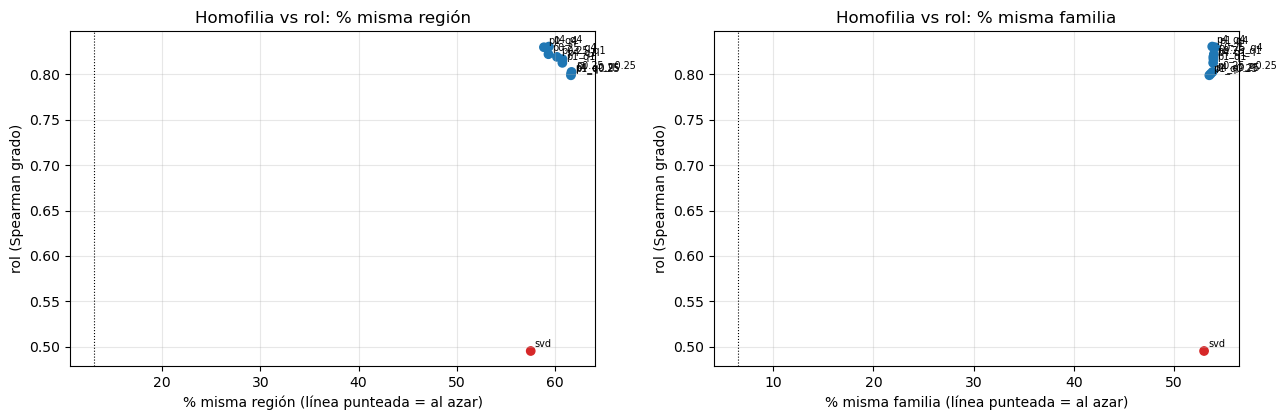

In [4]:
d_ = perfil.set_index("config")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a_, x in zip(ax, ["% misma región", "% misma familia"]):
    sin_azar = d_.drop("al azar")
    a_.scatter(sin_azar[x], sin_azar["rol (Spearman grado)"], c=["tab:red" if c == "svd" else "tab:blue" for c in sin_azar.index])
    for c, r in sin_azar.iterrows():
        a_.annotate(c, (r[x], r["rol (Spearman grado)"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    a_.axvline(d_.loc["al azar", x], color="k", ls=":", lw=.8)
    a_.set(xlabel=f"{x} (línea punteada = al azar)", ylabel="rol (Spearman grado)", title=f"Homofilia vs rol: {x}")
mostrar_fig("homofilia_vs_rol")

- **Los embeddings capturan sobre todo mercado:** 60% de vecinos de la misma región y 54% de la misma familia

- **p y q mueven el equilibrio en la dirección de la teoría** (DFS → región, BFS → rol)

- **Por qué p y q pesan tan poco aquí:** la co-participación crea un **clique por proceso**

- El vecindario inmediato y la comunidad casi coinciden, y Word2Vec termina viendo los mismos contextos

- **SVD** captura el rubro casi igual (53% familia) pero no la posición estructural (rol 0.50 vs 0.80-0.83)

---
### **2. Convergencia con las partes anteriores**

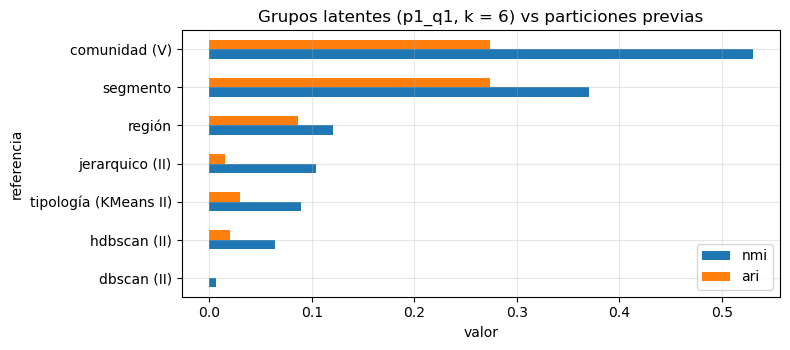

,n,ari,nmi,pureza
referencia,,,,
región,56948,0.086,0.121,0.366
segmento,55212,0.274,0.370,0.458
tipología (KMeans II),11662,0.030,0.089,0.681
dbscan (II),11662,-0.001,0.006,0.975
hdbscan (II),11662,0.020,0.064,0.682
jerarquico (II),4360,0.015,0.104,0.835
comunidad (V),7114,0.274,0.530,0.375


In [5]:
ref = conv[conv.config == config["conf_ref"]].set_index("referencia")[["n", "ari", "nmi", "pureza"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ref[["nmi", "ari"]].sort_values("nmi").plot.barh(ax=ax)
ax.set(xlabel="valor", title=f"Grupos latentes ({config['conf_ref']}, k = {config['k_lat']}) vs particiones previas")
mostrar_fig("convergencia_resumen")
ref.round(3)

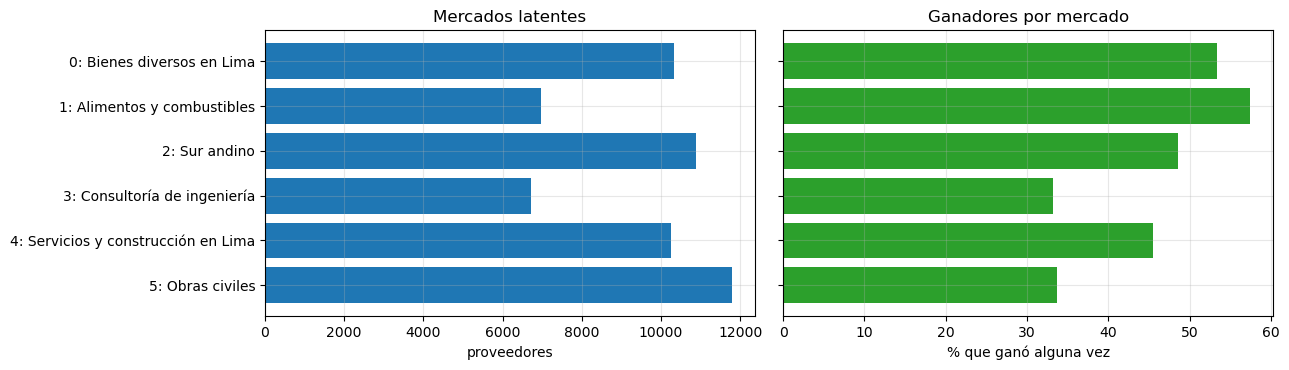

In [6]:
def nombre_mercado(r):
    seg, reg = str(r.segmento), str(r.region)
    pct_seg = float(seg.split("(")[1].rstrip("%)")) if "(" in seg else 0
    if seg.startswith("81"):
        return "Consultoría de ingeniería"
    if seg.startswith(("50", "15")):
        return "Alimentos y combustibles"
    if reg.startswith("CUSCO"):
        return "Sur andino"
    if seg.startswith("72") and pct_seg >= 80:
        return "Obras civiles"
    if seg.startswith("72"):
        return "Servicios y construcción en Lima"
    return "Bienes diversos en Lima"

pl = perfiles_lat.set_index("grupo")
et = [f"{g}: {nombre_mercado(r)}" for g, r in pl.iterrows()]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(et, pl.proveedores, color="tab:blue"); ax[0].set(xlabel="proveedores", title="Mercados latentes")
ax[1].barh(et, 100 * pl.pct_gano, color="tab:green"); ax[1].set(xlabel="% que ganó alguna vez", title="Ganadores por mercado")
ax[1].set_yticklabels([])
for a_ in ax:
    a_.invert_yaxis()
mostrar_fig("mercados_latentes")

- **Mercados latentes:** obras civiles (grupo 5) y el sur andino (grupo 2) son los más grandes

- **Obras y consultoría** tienen la menor fracción de ganadores (~33-34%), alimentos y combustibles la mayor (57%)

In [7]:
if comunidades is not None:
    display(tabla("c_proyeccion", "cruce_v").round(3))

,config,k,nmi,ari,anidamiento
0,p1_q1,6,0.530,0.274,0.828
1,p1_q1,41,0.761,0.518,0.653
2,p0.25_q4,6,0.530,0.274,0.839
3,p0.25_q4,41,0.769,0.534,0.668
4,p4_q0.25,6,0.533,0.272,0.842
5,p4_q0.25,41,0.767,0.563,0.682
6,svd,6,0.538,0.244,0.895
7,svd,41,0.750,0.605,0.739


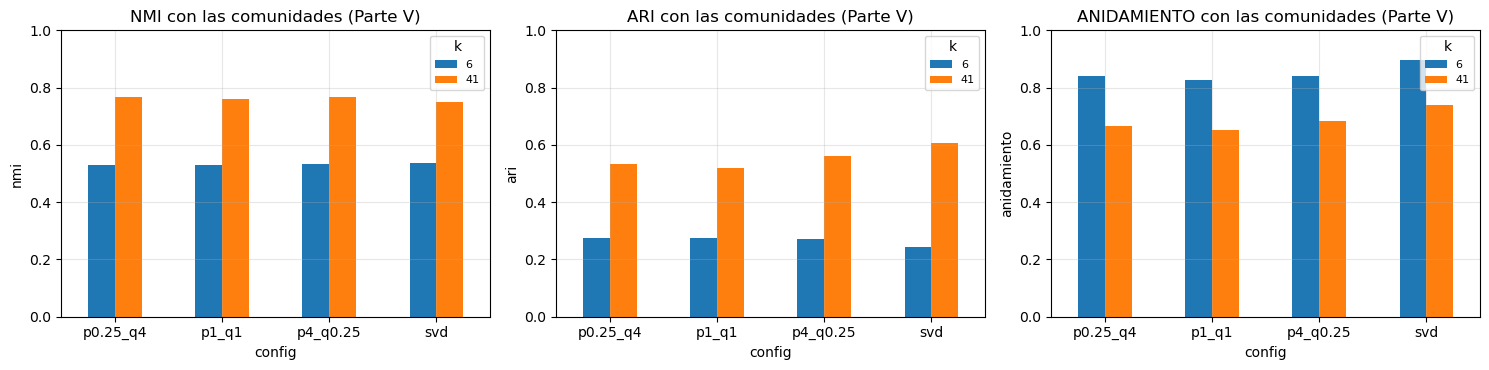

In [8]:
if comunidades is not None:
    cv = tabla("c_proyeccion", "cruce_v")
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for a_, met in zip(ax, ["nmi", "ari", "anidamiento"]):
        cv.pivot(index="config", columns="k", values=met).plot.bar(ax=a_, rot=0)
        a_.set(ylim=(0, 1), ylabel=met, title=f"{met.upper()} con las comunidades (Parte V)"); a_.legend(title="k", fontsize=8)
    mostrar_fig("convergencia_v")

- k = 6 el anidamiento es alto (0.83-0.90) y el NMI 0.53

- k = 41 el NMI sube a 0.75-0.77 y el ARI a 0.52-0.61, con las 4 configuraciones casi iguales

| Parte | Qué agrupa | Convergencia con el embedding | Lectura |
|---|---|---|---|
| II – Tipologías (KMeans, Ward, HDBSCAN) | **Comportamiento**: tamaño, competencia, dependencia | Baja (NMI 0.06-0.10) | Embedding dice **dónde** compite, la tipología **cómo** |
| II – "Contratistas" | Rubro (`pct_obras`) | Alta: 45% del grupo de obras | La única tipología basada en rubro es la que coincide |
| IV – PageRank / HITS | **Peso** en la red de compras | PageRank se reparte en todos los grupos | Cada mercado tiene sus centrales; HITS marca el núcleo de salud |
| V – Comunidades (Louvain) | **Mercados densos** del núcleo de co-participación | **La más alta:** NMI 0.53 (k = 6) y 0.75-0.77 (k = 41); anidamiento 0.83 | Misma estructura por dos caminos; el embedding la extiende a la periferia |

---
### **3. Predicción de enlaces**

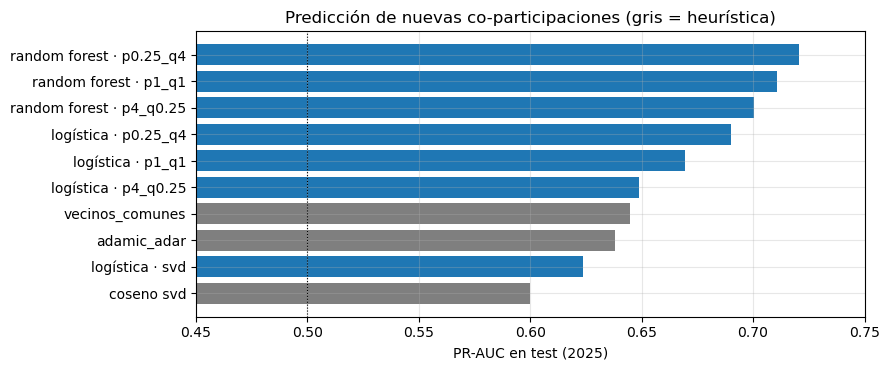

,negativos,roc_auc,roc_auc_adamic_adar
0,neg al azar,0.8835,0.8331
1,neg 2 saltos,0.6032,0.4315


In [9]:
mejor_por = (res.assign(familia=np.where(res.modelo == "base", res.config, res.modelo + " · " + res.config))
                .sort_values("pr_auc", ascending=False).drop_duplicates("familia").head(10))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(mejor_por.familia[::-1], mejor_por.pr_auc[::-1], color=["tab:gray" if m == "base" else "tab:blue" for m in mejor_por.modelo[::-1]])
ax.axvline(.5, color="k", ls=":", lw=.8)
ax.set(xlim=(.45, .75), xlabel="PR-AUC en test (2025)", title="Predicción de nuevas co-participaciones (gris = heurística)")
mostrar_fig("enlaces_resumen")
por_tipo

In [10]:
prec_top

,top,% aparece en 2025
0,30,13.33
1,100,11.00
2,1000,7.30
3,10000,5.22
4,300000,1.32


- **El embedding anticipa nuevas co-participaciones** mejor que las heurísticas (PR-AUC 0.72 vs 0.64)

- **Su ventaja está en el caso difícil:** entre pares que ya comparten un competidor, embedding discrimina (0.60)

- **Utilidad práctica limitada y honesta:** en el top 100 solo el 9% aparece en 2025; es un ×7 sobre la base

- El mercado se renueva mucho (73-78% de aristas nuevas por año)

---
### **4. Preguntas de interés**

**PQ2 – ¿Qué mercados emergen de la co-participación? ¿Son regionales o por rubro?**

- **Por rubro primero, por región después:** el NMI con el segmento (0.37) triplica al de la región (0.12)

- Mercados: obras civiles, ingeniería, alimentos, bienes diversos, servicios de construcción en Lima y el **sur andino**

- El sur andino es el único mercado definido sobre todo por geografía: obras + materiales de construcción de proveedores locales

- **Obras y consultoría** tienen la menor fracción de proveedores que alguna vez ganan (33-34%)

**PQ3 – ¿Qué proveedores son alternativas y qué afinidades son inusuales?**

- Los **vecinos del embedding** son sustitutos por posición: compiten en procesos que los competidores

- Los **enlaces predichos** apuntan a sustitutos que aún no se cruzaron

- Sobre todo **distribuidores farmacéuticos y de insumos médicos de Lima**

---
### **5. Variación de los resultados**

| Parámetro | Rango probado | Efecto |
|---|---|---|
| Hubs retirados | 0-1% | Con 0.1% se van los postores masivos (11.4% de la masa) |
| Dimensión | 32, 64, 128 | 32 separa mejor los pares futuros (AUC 0.879 vs 0.853) |
| p, q | 0.25-4 | ±3 puntos de homofilia y ±0.03 de rol; PR-AUC ±0.01-0.02; del orden del ruido entre semillas |
| Semilla | 42 vs 7 | Comparten 28% de los 10 vecinos, pero el perfil agregado es el mismo |
| `n_neighbors` UMAP | 15, 30, 50 | Confiabilidad 0.983-0.986: la proyección es robusta |
| *k* latente | 4-20 | Solo k = 6 es estable (ARI 0.996); con k = 4 y desde k = 8, 0.49-0.81 |
| Operador de par | Hadamard, L1, L2 | Solo Hadamard supera a las heurísticas |

---
### **6. Síntesis**

| Pregunta | Hallazgo |
|---|---|
| ¿Qué técnica? | Node2Vec (p × q, 32 dimensiones) sobre co-participación sin postores masivos; SVD como referencia lineal |
| ¿Qué capturan? | **Mercado** (rubro, luego región) y en menor medida **rol**; p y q casi no cambian el resultado |
| ¿Convergen con clustering? | Poco (NMI ≈ 0.09): posición en el mercado vs comportamiento; solo coinciden en obras |
| ¿Y con PageRank? | Ortogonales: el embedding dice dónde compite un proveedor, PageRank cuánto pesa |
| ¿Y con Comunidad? | Alta (NMI 0.75-0.77 a igual k): las comunidades se anidan en los 6 mercados latentes |
| ¿Sirven para predecir? | Sí, mejor que las heurísticas (PR-AUC 0.72 vs 0.64), sobre todo en pares difíciles; con precisión absoluta baja |
| ¿PQ2? | Mercados por rubro y luego región; el sur andino como mercado regional |
| ¿PQ3? | Sustitutos por posición y pares afines que aún no compiten (salud en Lima) |

---
### **7. Escritura de resultados**

`hallazgos_web`: los tres hallazgos interactivos y qué artefacto lee la web para cada uno

In [11]:
hallazgos_web = pd.DataFrame([
    {"hallazgo": "Mercados en el espacio latente", "pregunta": "PQ2", "control": "p, q de Node2Vec y k de KMeans",
     "artefacto": "c_proyeccion/web/umap_web.json + nodos_web.json"},
    {"hallazgo": "Qué capturan p y q (homofilia vs rol)", "pregunta": "PQ2", "control": "p, q",
     "artefacto": "b_node2vec/web/perfil_pq.json"},
    {"hallazgo": "Pares afines que aún no compiten", "pregunta": "PQ3", "control": "top-N y umbral de probabilidad",
     "artefacto": "d_enlaces/web/top_pares.json + precision_top.json"}])
escritos = guardar_tablas({"convergencia_ref": ref.reset_index(), "enlaces_resumen": mejor_por, "hallazgos_web": hallazgos_web})

Escrito en 06_Representacion/temp/e_analisis/: convergencia_ref, enlaces_resumen, hallazgos_web


#### a. Verificación

In [12]:
verificar_salidas(escritos)

OK: 3 tablas (parquet + json) | 5 figuras: convergencia_resumen, convergencia_v, enlaces_resumen, homofilia_vs_rol, mercados_latentes


---
### **8. Cerrar sesión**

In [13]:
spark.stop()